# Pattern proof (delivery plan, step 1.21): scope-gate evidence

For each envelope, the baseline arm is simulated for a year and written to `runs/s<n>_baseline.duckdb`. Everything below is read **through `engine.db.connect_for_tools`**, the connection agent tools get: no scenario file, no truth. Only the last section opens `demo/truth/`, the way the Rivelazione screen does.

The pattern-3 segment (75+, living alone, over 40 km) comes from the Solution Plan's description, not from the scenario files. Queries: `src/sim/pattern_proof.py`; the same check runs in `testing/test_patterns.py`.

Re-run (about 1 minute): `uv run jupyter nbconvert --to notebook --execute --inplace testing/notebooks/patterns.ipynb`

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from engine.db import connect_for_tools
from sim import pattern_proof as pp
from sim.run import run
from sim.truth import TRUTH_DIR

DAYS, SCENARIOS = 365, (1, 2, 3)
for n in SCENARIOS:
    stats = run(f's{n}_baseline', days=DAYS, overwrite=True)
    print(f'scenario {n}: {stats["sim_ms_mean"]:.1f} ms simulated per day, {stats["events_per_day"]:.0f} events a day')
con = {n: connect_for_tools(f's{n}_baseline') for n in SCENARIOS}

scenario 1: 5.6 ms simulated per day, 2979 events a day


scenario 2: 5.9 ms simulated per day, 3002 events a day


scenario 3: 5.6 ms simulated per day, 2998 events a day


## Pattern 1: echo bottleneck at one hospital, free slots at another

Mean days from booking to echo slot, by week. One hospital climbs to about six weeks around day 35 (alarm, step 2.8) and is capped at 60 days, when patients stop booking; the others stay at about two days.

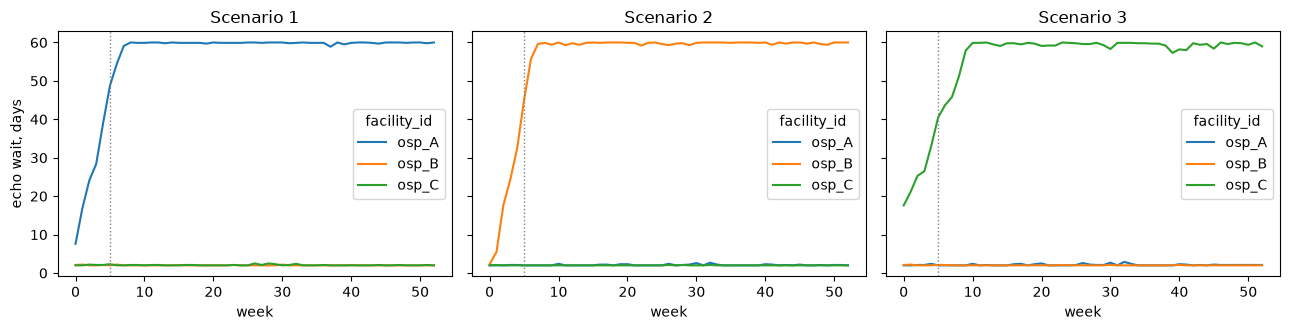

,scenario 1,scenario 2,scenario 3
wait d30–40 osp_A,44.6,2.0,2.2
wait d30–40 osp_B,2.1,39.2,2.0
wait d30–40 osp_C,2.3,2.0,37.4
free slots d36–56 osp_A,0.0,44.0,39.0
free slots d36–56 osp_B,48.0,0.0,55.0
free slots d36–56 osp_C,30.0,67.0,0.0


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, n in zip(axes, SCENARIOS):
    pp.echo_wait_weekly(con[n], DAYS).plot(ax=ax, title=f'Scenario {n}')
    ax.axvline(5, color='grey', ls=':', lw=1); ax.set_xlabel('week'); ax.set_ylabel('echo wait, days')
plt.tight_layout(); plt.show()
pd.DataFrame({f'scenario {n}': {**{f'wait d30–40 {k}': v for k, v in pp.echo_wait(con[n], 30, 40).items()},
                                **{f'free slots d36–56 {k}': v for k, v in pp.free_echo_slots(con[n], 35).items()}}
              for n in SCENARIOS})

## Pattern 2: one MMG cooperative does not collect furosemide and is readmitted more

Drug collections and admissions per patient-year, by cooperative. One cooperative stands out in each scenario.

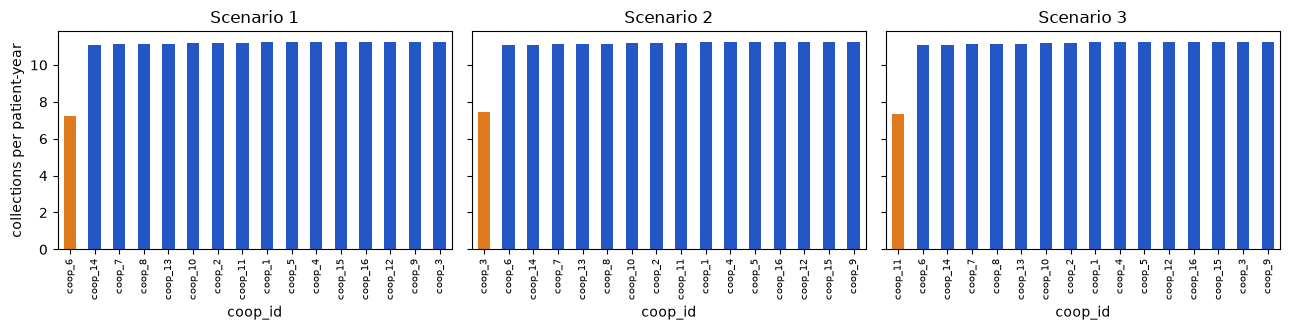

patients  collections_per_year  admissions_per_year
           coop_id                                                     
scenario 1 coop_6        471                  7.25                0.484
           coop_14       548                 11.09                0.338
           coop_7        535                 11.14                0.417
scenario 2 coop_3        660                  7.47                0.438
           coop_6        471                 11.08                0.359
           coop_14       548                 11.09                0.336
scenario 3 coop_11       609                  7.36                0.484
           coop_6        471                 11.08                0.359
           coop_14       548                 11.09                0.336

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, n in zip(axes, SCENARIOS):
    c = pp.cooperatives(con[n], DAYS).set_index('coop_id')
    colors = ['#e07a1f' if i == 0 else '#2457c5' for i in range(len(c))]
    c.collections_per_year.plot.bar(ax=ax, color=colors, title=f'Scenario {n}')
    ax.set_ylabel('collections per patient-year'); ax.tick_params(axis='x', labelsize=7)
plt.tight_layout(); plt.show()
pd.concat({f'scenario {n}': pp.cooperatives(con[n], DAYS).head(3).set_index('coop_id') for n in SCENARIOS})

## Pattern 3: older patients living alone far away stop telemonitoring in a group of rural comuni

Among segment patients ever on telemonitoring, the share still sending readings in the last week of the year, by comune (comuni with at least 2 such patients). This is the weakest signal: few patients.

In [4]:
pd.concat({f'scenario {n}': pp.telemonitoring_by_comune(con[n], DAYS - 1).query('patients >= 2').head(8)
           .reset_index(drop=True) for n in SCENARIOS}, axis=1)

scenario 1                                       scenario 2  \
                     comune patients share_reading                    comune   
0                   Spineda        4        0.0000        Sermide e Felonica   
1                 Calvatone        2        0.0000              Poggio Rusco   
2  Rivarolo del Re ed Uniti        2        0.0000            Borgocarbonara   
3             Casalmaggiore       23        0.0435                   Spineda   
4            Borgocarbonara        6        0.5000                 Casalmoro   
5                 Casalmoro        4        0.5000             Casalmaggiore   
6        Canneto sull'Oglio        8        0.6250  Rivarolo del Re ed Uniti   
7        Sermide e Felonica       11        0.6364        Canneto sull'Oglio   

                                        scenario 3                         
  patients share_reading                    comune patients share_reading  
0       11        0.0909        Canneto sull'Oglio        7        0.0000  
1        8        0.1250                 Solferino        6        0.0000  
2        5        0.2000               Casalromano        2        0.0000  
3        4        0.5000                 Casalmoro        4        0.2500  
4        4        0.5000            Borgocarbonara        6        0.5000  
5       38        0.5263                   Spineda        4        0.5000  
6        5        0.6000             Casalmaggiore       38        0.5263  
7        8        0.6250  Rivarolo del Re ed Uniti        5        0.6000

## PNE calibration from the data

30-day readmission (SPEC §5.2) in each scenario; target about 12%, every hospital within 10–16%.

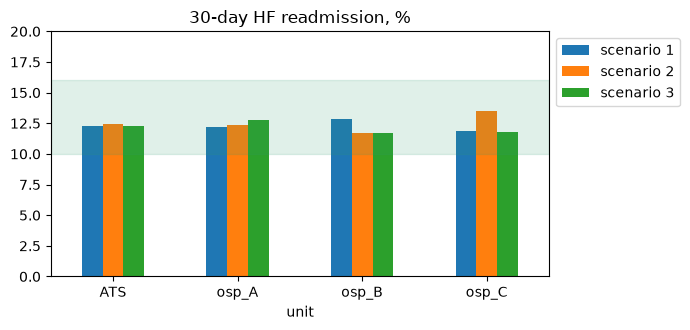

,scenario 1,scenario 2,scenario 3
unit,,,
ATS,0.1231,0.1243,0.1231
osp_A,0.1216,0.1235,0.1280
osp_B,0.1286,0.1167,0.1167
osp_C,0.1186,0.1353,0.1182


In [5]:
pne = pd.concat({f'scenario {n}': pp.readmission_30d(con[n], DAYS).set_index('unit').rate for n in SCENARIOS}, axis=1)
ax = (pne * 100).plot.bar(figsize=(7, 3.4), rot=0, title='30-day HF readmission, %')
ax.axhspan(10, 16, color='#2f9e6e', alpha=0.15); ax.set_ylim(0, 20)
ax.legend(loc='upper left', bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show(); pne

## Rivelazione: what the data says against what the envelope hides

`detect` names each place from the data alone; only now `demo/truth/` is opened.

In [6]:
rows = []
for n in SCENARIOS:
    found = pp.detect(con[n], DAYS)
    truth = json.loads((TRUTH_DIR / f'scenario_{n}.json').read_text(encoding='utf-8'))
    match = pp.compare(found, truth)
    truth_flat = {'echo_bottleneck': truth['echo_bottleneck']['facility_id'],
                  'echo_free_capacity': truth['echo_free_capacity']['facility_id'],
                  'low_adherence_group': truth['low_adherence_group']['coop_id'],
                  'rural_dropout_comuni': truth['rural_dropout_comuni']}
    for k in found:
        rows.append({'scenario': n, 'pattern': k, 'found in data': found[k], 'envelope': truth_flat[k], 'match': match[k]})
for c in con.values():
    c.close()
result = pd.DataFrame(rows)
print(f"{result.match.sum()} of {len(result)} matched")
result

12 of 12 matched


,scenario,pattern,found in data,envelope,match
0,1,echo_bottleneck,osp_A,osp_A,True
1,1,echo_free_capacity,osp_B,osp_B,True
2,1,low_adherence_group,coop_6,coop_6,True
3,1,rural_dropout_comuni,"[Calvatone, Casalmaggiore, Rivarolo del Re ed ...","[Martignana di Po, Tornata, Calvatone, Casalma...",True
4,2,echo_bottleneck,osp_B,osp_B,True
5,2,echo_free_capacity,osp_C,osp_C,True
6,2,low_adherence_group,coop_3,coop_3,True
7,2,rural_dropout_comuni,"[Borgocarbonara, Poggio Rusco, Sermide e Felon...","[Poggio Rusco, Magnacavallo, Borgocarbonara, S...",True
8,3,echo_bottleneck,osp_C,osp_C,True
9,3,echo_free_capacity,osp_B,osp_B,True
